# Fig. 1b-h: dI/dV spectra and maps across a stacking domain wall


    Panels **b, c**: dI/dV spectra averaged over the rhombohedral (+⁵) and the stacking-fault (+⁴−)
    regions of the grid-spectroscopy map, compared with the tight-binding surface density of states.
    Panels **d-h**: dI/dV maps of the same grid at different sample biases.

    Data: the RHK `.sm4` grid spectroscopy file `MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4`
    (6-layer sample, 9 K; 64 × 64 spectra, 330 bias points, forward and backward sweeps) and the
    tight-binding surface DOS of the two stackings (`TB_DOS_E.txt`, `Konrad_rhombo.txt`, `Konrad_hexag.txt`).
    Panel a is a schematic and is not generated here.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import rhkpy
import xarray as xr

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('rhkpy', rhkpy.__version__)
print('xarray', xr.__version__)

python 3.13.5
numpy 2.3.1
matplotlib 3.10.3
rhkpy 1.3.10
xarray 2025.6.1


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4', 'TB_DOS_E.txt', 'Konrad_rhombo.txt', 'Konrad_hexag.txt']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

  saved to data/MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4
  saved to data/TB_DOS_E.txt
  saved to data/Konrad_rhombo.txt
  saved to data/Konrad_hexag.txt


## Load the grid spectroscopy map

In [11]:
map_991 = rhkpy.rhkdata(get_data('MK_ABC_FLG_25_9K_2023_10_31_08_48_27_991.sm4'))
print(dict(map_991.spectra.sizes))

{'bias': 330, 'specpos_y': 64, 'specpos_x': 64, 'repetitions': 1, 'biasscandir': 2}


## Processing

Mean over the repetitions and the two bias sweep directions, normalization to the current at the
first bias point (the stabilization set point), then a 5-point running mean along the bias axis
and a 3 × 3 running mean in position.

In [12]:
map_991_mean = map_991.mrep().msw()
map_norm = map_991_mean.spectra.lia / map_991_mean.spectra.current[0, :, :]
map_norm_biasavg = map_norm.rolling(bias=5, center=True).mean()
map_norm_avg = map_norm_biasavg.rolling(specpos_x=3, specpos_y=3, center=True).mean()

## Panels b, c: averaged spectra versus the tight-binding DOS

The spectra are averaged over the rectangles marked in Fig. 1f (map coordinates in nm).
The TB curves are offset vertically for clarity, as in the figure.

In [13]:
E = np.loadtxt(get_data('TB_DOS_E.txt'))
rhombo = np.loadtxt(get_data('Konrad_rhombo.txt'))   # TB surface DOS of (+5), ABCABC
hexag = np.loadtxt(get_data('Konrad_hexag.txt'))     # TB surface DOS of (+4-), ABCABA

REGION_RG = dict(specpos_y=slice(-55, -20), specpos_x=slice(200, 215))   # (+5), blue rectangle
REGION_SF = dict(specpos_y=slice(-55, -20), specpos_x=slice(150, 167))   # (+4-), red rectangle
avg_dims = ['specpos_y', 'specpos_x', 'repetitions', 'biasscandir']

rhomb_avg = map_991.spectra.sel(**REGION_RG).mean(dim=avg_dims).lia
hexag_avg = map_991.spectra.sel(**REGION_SF).mean(dim=avg_dims).lia

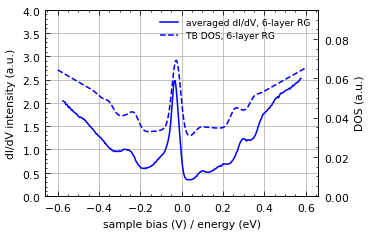

In [14]:
def spectrum_vs_tb(exp, tb, tb_offset, tb_ylim, color, label_exp, label_tb, figsize=(3.2, 2.2)):
    fig, ax1 = plt.subplots(figsize=figsize)
    l1, = ax1.plot(exp.bias.values, exp.values, color=color, lw=1.0, label=label_exp)
    ax1.set_xlabel('sample bias (V) / energy (eV)')
    ax1.set_ylabel('dI/dV intensity (a.u.)')
    ax1.set_ylim(0, 4)
    ax2 = ax1.twinx()
    l2, = ax2.plot(E, tb + tb_offset, color=color, ls='--', lw=1.0, label=label_tb)
    ax2.set_ylim(0, tb_ylim)
    ax2.set_ylabel('DOS (a.u.)')
    ax1.legend([l1, l2], [l1.get_label(), l2.get_label()], fontsize=6)
    ax1.grid(True)
    return fig


# panel b: rhombohedral (+5)
spectrum_vs_tb(rhomb_avg, rhombo, 0.03, 0.095, 'blue',
               'averaged dI/dV, 6-layer RG', 'TB DOS, 6-layer RG')
plt.show()

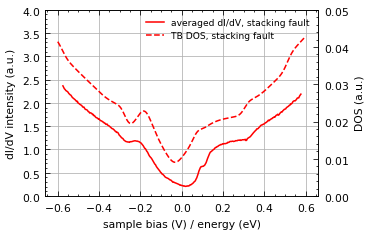

In [15]:
# panel c: stacking fault (+4-)
spectrum_vs_tb(hexag_avg, hexag, 0.0075, 0.05, 'red',
               'averaged dI/dV, stacking fault', 'TB DOS, stacking fault')
plt.show()

## Panels d-h: dI/dV maps at different biases

The sign of the lock-in signal is flipped and the map is scaled by 1000. The colour limits of
each panel are those of the figure; the figure shows five of the six biases plotted here.
The map is 108 nm wide (scale bar of 25 nm in Fig. 1e).

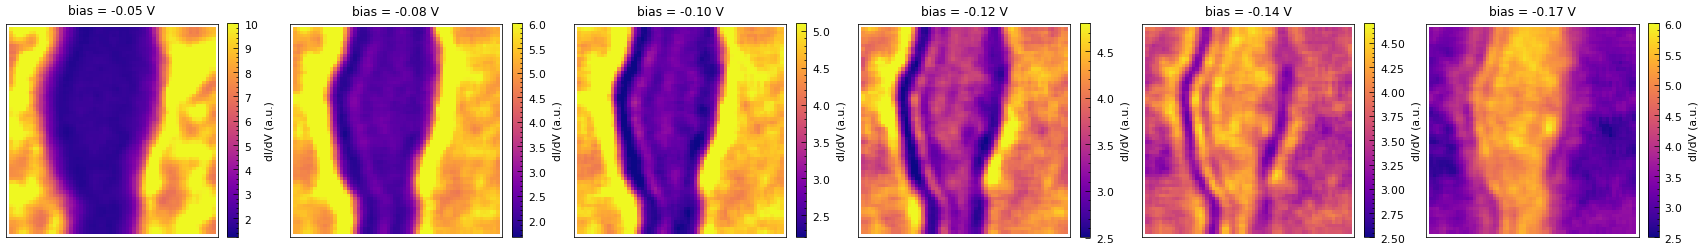

In [16]:
BIASES = [-0.05, -0.08, -0.10, -0.12, -0.14, -0.17]   # V
CLIMS = [(1.20, 10.0), (1.65, 6.0), (2.20, 5.1), (2.50, 4.8), (2.50, 4.7), (2.50, 6.0)]

dIdV = -map_norm_avg * 1000
dIdV = dIdV.assign_coords(specpos_x=dIdV.specpos_x - dIdV.specpos_x.min(),
                          specpos_y=dIdV.specpos_y - dIdV.specpos_y.min())
x, y = dIdV.specpos_x.values, dIdV.specpos_y.values
extent = [x.min(), x.max(), y.min(), y.max()]

fig, axs = plt.subplots(1, len(BIASES), figsize=(2.6 * len(BIASES), 3.0))
for ax, bias, clim in zip(axs, BIASES, CLIMS):
    panel = dIdV.sel(bias=bias, method='nearest').transpose('specpos_y', 'specpos_x')
    im = ax.imshow(panel.values, cmap='plasma', origin='lower', extent=extent,
                   vmin=clim[0], vmax=clim[1], aspect='equal')
    ax.set_title(f'bias = {float(panel.bias):.2f} V', fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='dI/dV (a.u.)')
plt.tight_layout()
plt.show()